## 1. Installation and Import of Python Packages

https://pytorch.org

In [1]:
!pip install -q torch

In [2]:
!pip install -q torchvision

In [3]:
!pip install -q torchsummary

In [4]:
!pip install -q -U watermark

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 4.9/4.9 MB 52.6 MB/s eta 0:00:00


In [5]:
# Imports
import torch
import torch.nn as nn
import torch.nn.functional as F
import torch.optim as optim
import torchvision
import torchvision.transforms as transforms
import matplotlib.pyplot as plt
import numpy as np
from PIL import Image
from io import BytesIO
from torchsummary import summary

In [7]:
%reload_ext watermark
%watermark -a "Paulo C. Faria" --iversions

Author: Paulo C. Faria

PIL         : 11.3.0
matplotlib  : 3.10.0
numpy       : 2.1.3
torch       : 2.11.0+cu130
torchsummary: 1.5.1
torchvision : 0.26.0+cu130



## 2. Setting the Device (CPU or GPU) for AI Model Training


Hardware configurations:

**Google Colab Free**

- CPU: Intel(R) Xeon(R) CPU @ 2.00GHz 2-Core CPU
- System RAM: 12 GB RAM
- GPU: Tesla T4 ( T4 15 GB )
- SSD Disk

In [8]:
# Device selection block (CUDA, MPS or CPU)

if torch.cuda.is_available():
    # Priority 1: NVIDIA GPU (CUDA)
    device = torch.device("cuda")
    print("Selected device: NVIDIA GPU (CUDA)")

elif torch.backends.mps.is_available():
    # Priority 2: Apple GPU (MPS)
    device = torch.device("mps")
    print("Selected device: Apple GPU (MPS)")

else:
    # Fallback: CPU
    device = torch.device("cpu")
    print("Selected device: CPU")

print(f'Selected device: {device}')

Selected device: NVIDIA GPU (CUDA)
Selected device: cuda


In [10]:
# Model hyperparameters
num_epochs = 10         # Number of epochs to train
batch_size = 64         # Batch size
learning_rate = 0.001   # Learning rate

In [11]:
# Define the transformations for the data
transformacoes = transforms.Compose([transforms.ToTensor(), transforms.Normalize((0.5, 0.5, 0.5), (0.5, 0.5, 0.5))])

In [12]:
# Download and load the training dataset
dataset_treino = torchvision.datasets.CIFAR10(root = './dados',
                                                  train = True,
                                                  download = True,
                                                  transform = transformacoes)

100%|██████████| 170M/170M [02:50<00:00, 1.00MB/s]


In [13]:
# Download and load the test dataset
dataset_teste = torchvision.datasets.CIFAR10(root = './dados',
                                                 train = False,
                                                 download = True,
                                                 transform = transformacoes)

In [14]:
# Create the DataLoaders to load the data in batches
loader_treino = torch.utils.data.DataLoader(dataset_treino,
                                                batch_size = batch_size,
                                                shuffle = True)

loader_teste = torch.utils.data.DataLoader(dataset_teste,
                                               batch_size = batch_size,
                                               shuffle = False)

In [15]:
# Define CIFAR-10 classes
classes = ('plane', 'car', 'bird', 'cat', 'deer', 'dog', 'frog', 'horse', 'ship', 'truck')

In [16]:
print(f"Number of training images: {len(dataset_treino)}")
print(f"Number of test images: {len(dataset_teste)}")
print(f"Number of training batches: {len(loader_treino)}")
print(f"Number of test batches: {len(loader_teste)}")

Number of training images: 50000
Number of test images: 10000
Number of training batches: 782
Number of test batches: 157


<!-- Work developed in the Data Science Academy Course - www.datascienceacademy.com.br -->

## 5. Visualising the Loaded Images

In [17]:
# Function to display the image
def imshow(img):
    img = img / 2 + 0.5
    npimg = img.numpy()
    plt.imshow(np.transpose(npimg, (1, 2, 0)))
    plt.show()

In [18]:
# Get a batch of training images
dataiter = iter(loader_treino)
images, labels = next(dataiter)

Training image sample:


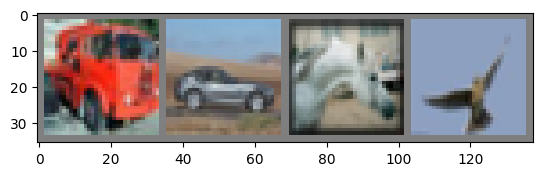

Labels:  truck car   horse bird 


In [19]:
# Show the first 4 images of the batch
print("Training image sample:")
imshow(torchvision.utils.make_grid(images[:4]))

# Print the corresponding labels
print('Labels: ', ' '.join(f'{classes[labels[j]]:5s}' for j in range(4)))

## 6. AI Model Construction

The cell below defines the architecture of a Convolutional Neural Network (CNN), a classic AI model used for image classification.

https://www.deeplearningbook.com.br/introducao-as-redes-neurais-convolucionais/

Briefly, it is divided into two parts:

**__init__(self) (The Network's "Blueprint"):**

* This function is the "constructor" that declares all the layers (the "pieces") that the network will use.
* self.conv1 and self.conv2: These are convolutional layers that act as "feature extractors", learning to identify patterns (such as edges, textures) in the image.
* self.pool: This is a pooling layer that reduces the image size (from 28x28 to 14x14, and from 10x10 to 5x5), making the model more efficient and focused on the most important features.
* self.fc1, fc2, fc3: These are linear (fully connected) layers that act as the decision-making "brain". They receive the flattened features (16 * 5 * 5 = 400) and use them to classify the image. The final layer (fc3) has 10 outputs, one for each final category (e.g., "cat", "dog", "airplane", etc.).

**forward(self, x) (The "Assembly Line"):**

* This function defines the exact order in which the data (x, the input image) passes through the layers.
* The flow is: Convolution 1 -> ReLU activation -> Pooling -> Convolution 2 -> ReLU activation -> Pooling.
* After extracting the features, the data is flattened to become a long vector.
* This vector passes through the decision layers (fc1, fc2, fc3) to produce the final classification result.

In [20]:
# Class to create the model architecture
class ConvNet(nn.Module):

    # Constructor method
    def __init__(self):

        # Initialise the parent class constructor
        super(ConvNet, self).__init__()

        # Input: 3 colour channels, Output: 6 feature maps, Kernel: 5x5
        self.conv1 = nn.Conv2d(3, 6, 5)

        # Max pooling 2x2
        self.pool = nn.MaxPool2d(2, 2)

        # Input: 6 channels (from conv1), Output: 16 feature maps, Kernel: 5x5
        self.conv2 = nn.Conv2d(6, 16, 5)

        # CIFAR-10 images are 32x32
        # After conv1 (5x5): 32-5+1 = 28 -> 28x28
        # After pool1 (2x2): 28/2 = 14 -> 14x14
        # After conv2 (5x5): 14-5+1 = 10 -> 10x10
        # After pool2 (2x2): 10/2 = 5 -> 5x5
        # Flattened size: 16 channels * 5 * 5 = 400 features

        # Fully connected layers (Linear)
        self.fc1 = nn.Linear(16 * 5 * 5, 120) # 400 -> 120
        self.fc2 = nn.Linear(120, 84)         # 120 -> 84
        self.fc3 = nn.Linear(84, 10)          # 84 -> 10 (10 classes)

    # Forward method (feedforward pass)
    def forward(self, x):

        # Applying convolutional layers and pooling
        x = self.pool(F.relu(self.conv1(x)))
        x = self.pool(F.relu(self.conv2(x)))

        # Flatten the tensor for the linear layer
        # Flattens all dimensions except the batch
        x = torch.flatten(x, 1)

        # Applying linear layers with ReLU
        x = F.relu(self.fc1(x))
        x = F.relu(self.fc2(x))

        # Output layer (without activation, as CrossEntropyLoss applies Softmax)
        x = self.fc3(x)

        return x

In [21]:
# Let's instantiate the model and move it to the CPU to view a model summary
model = ConvNet().to("cpu")

In [22]:
print("Model Architecture:")
print(model)

Model Architecture:
ConvNet(
  (conv1): Conv2d(3, 6, kernel_size=(5, 5), stride=(1, 1))
  (pool): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
  (conv2): Conv2d(6, 16, kernel_size=(5, 5), stride=(1, 1))
  (fc1): Linear(in_features=400, out_features=120, bias=True)
  (fc2): Linear(in_features=120, out_features=84, bias=True)
  (fc3): Linear(in_features=84, out_features=10, bias=True)
)


In [23]:
# Summary
summary(model, (3, 32, 32), device = "cpu")

----------------------------------------------------------------
        Layer (type)               Output Shape         Param #
            Conv2d-1            [-1, 6, 28, 28]             456
         MaxPool2d-2            [-1, 6, 14, 14]               0
            Conv2d-3           [-1, 16, 10, 10]           2,416
         MaxPool2d-4             [-1, 16, 5, 5]               0
            Linear-5                  [-1, 120]          48,120
            Linear-6                   [-1, 84]          10,164
            Linear-7                   [-1, 10]             850
Total params: 62,006
Trainable params: 62,006
Non-trainable params: 0
----------------------------------------------------------------
Input size (MB): 0.01
Forward/backward pass size (MB): 0.06
Params size (MB): 0.24
Estimated Total Size (MB): 0.31
----------------------------------------------------------------


In [24]:
# Now we instantiate the model and move it to the training device (GPU/CPU)
model = ConvNet().to(device)

In [25]:
print(device)

cuda


## 7. Defining the Loss Function and Optimiser (Backpropagation)

This is the loss function (or "criterion"). It acts as a "ruler" that measures how far your model's predictions are from the correct answers.

In classification problems (such as "cat" vs "dog" vs "aeroplane"), CrossEntropyLoss is the standard metric. During training, it calculates a single number (the "loss") that indicates the magnitude of the error. The objective of all training is to minimise this number.

In [29]:
# Define the loss function. The model will seek parameters that reduce the overall error of the predictions.
criterion = nn.CrossEntropyLoss()

This is the optimiser. If the loss function is the "ruler" that measures the error, the optimiser is the "mechanic" that corrects the error.

The optimiser "looks" at the error (calculated by the criterion) and decides precisely how to adjust each parameter (weight) within modelo_dsa.parameters() to reduce this error in the next step.

Adam is a modern and very popular optimisation algorithm because it is efficient and adjusts automatically (adaptive), working well in most cases without requiring extensive manual tuning. The lr = learning_rate simply tells it how "aggressive" this adjustment should be.

In [26]:
# Adam optimiser
optimizer = optim.Adam(model.parameters(), lr = learning_rate)

## 8. Model Training

The cell below is the "heart" of the training and validation process for your AI model. In summary, it performs the following:

Main Epoch Loop (for epoch...): This is the external loop. It has the model "study" the entire training dataset multiple times (the number of times is defined by num_epochs).
<!-- Work developed in the Data Science Academy Course - www.datascienceacademy.com.br -->
Within each "Epoch", there are two phases:

**1. Training Phase (modelo_dsa.train())**

In this phase, the model learns from the data:

- for i, (images, labels)...: Takes training data in small batches (e.g., 64 images at a time).

- images.to(device): Moves the data to the GPU for rapid processing.

- outputs = modelo_dsa(images): (Forward) Makes model predictions for the image batch.

- loss = criterion(...): Calculates the "error" (how poor the predictions were) by comparing outputs with the correct labels.

- optimizer.zero_grad(): Clears error calculations from the previous step.

- loss.backward(): (Backward) Calculates "backwards" how each model weight contributed to that error (calculates gradients).

- optimizer.step(): Uses the optimiser (Adam) to adjust all model weights and reduce the error.

**2. Evaluation Phase (modelo_dsa.eval())**

After studying the training data once, the model "takes a test" to see what it has learned:

- modelo_dsa.eval(): Puts the model into evaluation mode (disables features like dropout).

- with torch.no_grad(): Disables gradient calculation (since we are not training), which saves significant memory and accelerates the process.

- for val_images, val_labels...: Takes data from the test set (data the model never saw during training).

- val_outputs = modelo_dsa(val_images): Makes predictions on the test data.

- n_correct += ...: Compares model predictions with correct answers and counts the total number of correct guesses.

**3. Progress Report**

- print(f'Epoch ...'): At the end of each epoch, it prints a summary: the average training error and test accuracy (percentage of correct predictions), allowing you to watch the model improve over time.

In [30]:
%%time

print("\nStarting training...\n")

# Calculate total steps per epoch (number of batches)
n_total_steps = len(loader_treino)

# Main training loop
for epoch in range(num_epochs):

    # Put the model in training mode
    model.train()

    # Initialise loss accumulator
    running_loss = 0.0

    # Iterate over training set batches
    for i, (images, labels) in enumerate(loader_treino):

        # Move tensors (images and labels) to the device (CPU or GPU), close to the model
        images = images.to(device)
        labels = labels.to(device)

        # Feedforward pass (forward)
        # Model prediction occurs here
        outputs = model(images)

        # Calculate model error
        loss = criterion(outputs, labels)

        # Zero accumulated gradients from previous iterations
        optimizer.zero_grad()

        # Calculate gradients via backpropagation
        loss.backward()

        # Update model weights
        optimizer.step()

        # Sum loss value for subsequent average calculation
        running_loss += loss.item()

    # After each epoch, evaluate the model on the test set (validation)
    # Put the model in evaluation mode
    model.eval()

    # Disable gradient calculation to save memory and time
    with torch.no_grad():

        n_correct = 0   # Correct predictions counter
        n_samples = 0   # Samples counter

        # Loop over test set
        for val_images, val_labels in loader_teste:

            # Move images and labels to device
            val_images = val_images.to(device)
            val_labels = val_labels.to(device)

            # Perform inference on test set
            val_outputs = model(val_images)

            # torch.max returns (value, index) → we take the index of the predicted class
            _, predicted = torch.max(val_outputs.data, 1)

            # Increment total samples
            n_samples += val_labels.size(0)

            # Increment number of correct predictions
            n_correct += (predicted == val_labels).sum().item()

    # Calculate accuracy and average epoch loss
    acc = 100.0 * n_correct / n_samples
    avg_loss = running_loss / n_total_steps

    # Display performance metrics for the current epoch
    print(f'Epoch [{epoch+1}/{num_epochs}], Training Loss: {avg_loss:.4f}, Test Accuracy: {acc:.2f} %')

# Display final completion message
print('\nTraining finished.\n')


Starting training...

Epoch [1/10], Training Loss: 1.6803, Test Accuracy: 47.58 %
Epoch [2/10], Training Loss: 1.3710, Test Accuracy: 51.26 %
Epoch [3/10], Training Loss: 1.2501, Test Accuracy: 57.23 %
Epoch [4/10], Training Loss: 1.1564, Test Accuracy: 59.03 %
Epoch [5/10], Training Loss: 1.0891, Test Accuracy: 60.93 %
Epoch [6/10], Training Loss: 1.0420, Test Accuracy: 61.42 %
Epoch [7/10], Training Loss: 0.9938, Test Accuracy: 62.69 %
Epoch [8/10], Training Loss: 0.9520, Test Accuracy: 63.38 %
Epoch [9/10], Training Loss: 0.9174, Test Accuracy: 62.10 %
Epoch [10/10], Training Loss: 0.8827, Test Accuracy: 63.86 %

Training finished.

CPU times: user 2min 52s, sys: 479 ms, total: 2min 52s
Wall time: 2min 54s


## 9. Model Evaluation

This code block is responsible for executing the final evaluation of the model using the test dataset, which it never saw during training. First, modelo_dsa.eval() puts the network into "evaluation mode", which disables specific training layers (such as dropout). Next, with torch.no_grad() disables gradient calculation since the model is no longer learning; this saves memory and significantly accelerates the inference process.

The code then iterates through all batches of loader_teste. For each batch, it makes predictions (outputs), uses torch.max to extract the class with the highest score (the final prediction, predicted), and compares it with the true labels (labels). It accumulates the total number of samples (n_samples) and the total number of correct predictions (n_correct) to calculate the overall model accuracy.

Simultaneously, the internal loop (for i in range(len(labels))) performs a more detailed analysis. It checks the result of each individual image to calculate per-class accuracy, populating the n_class_correct and n_class_samples lists. Finally, the script prints the overall accuracy (e.g., 85%) and then details the performance for each specific class (e.g., Class 'cat' accuracy: 90%, Class 'dog' accuracy: 75%), enabling a deeper analysis of where the model is succeeding or failing.

In [31]:
# Put the model in evaluation mode
model.eval()

# Disable gradient calculation (not required during evaluation)
with torch.no_grad():

    # Initialise total correct predictions counter
    n_correct = 0

    # Initialise total samples counter
    n_samples = 0

    # List to count correct predictions per class
    n_class_correct = [0 for _ in range(10)]

    # List to count total samples per class
    n_class_samples = [0 for _ in range(10)]

    # Loop over test set
    for images, labels in loader_teste:

        # Move images to device (CPU or GPU)
        images = images.to(device)

        # Move labels to the same device
        labels = labels.to(device)

        # Perform inference with the model
        outputs = model(images)

        # Obtain classes with highest probability
        _, predicted = torch.max(outputs, 1)

        # Increment total number of samples
        n_samples += labels.size(0)

        # Increment total number of correct predictions
        n_correct += (predicted == labels).sum().item()

        # Calculate accuracy per class
        for i in range(len(labels)):

            # Obtain true label
            label = labels[i]

            # Obtain predicted label
            pred = predicted[i]

            # If correct, increment class counter
            if (label == pred):
                n_class_correct[label] += 1

            # Increment total samples for the class
            n_class_samples[label] += 1

    # Calculate overall model accuracy
    acc_geral = 100.0 * n_correct / n_samples

    # Display overall accuracy result
    print(f'Overall model accuracy on test dataset: {acc_geral:.2f} %')

    # Print separator line
    print("-" * 30)

    # Loop to calculate and display accuracy for each class
    for i in range(10):

        # If there are samples for the class
        if n_class_samples[i] > 0:

            # Calculate class accuracy
            acc_classe = 100.0 * n_class_correct[i] / n_class_samples[i]

            # Display class accuracy
            print(f'Accuracy of class {classes[i]}: {acc_classe:.2f} %')

        # If no samples exist for the class
        else:

            # Indicate absence of data for the class
            print(f'Accuracy of class {classes[i]}: N/A (no samples)')

Overall model accuracy on test dataset: 63.86 %
------------------------------
Accuracy of class plane: 72.50 %
Accuracy of class car: 77.10 %
Accuracy of class bird: 49.70 %
Accuracy of class cat: 39.10 %
Accuracy of class deer: 64.10 %
Accuracy of class dog: 44.10 %
Accuracy of class frog: 71.00 %
Accuracy of class horse: 68.20 %
Accuracy of class ship: 76.50 %
Accuracy of class truck: 76.30 %


Let's save the model to disk.

In [32]:
PATH = './model_mp7.pth'
torch.save(model.state_dict(), PATH)
print(f'Model saved to: {PATH}')

Model saved to: ./model_mp7.pth


## 10. Deployment and Model Usage

In [33]:
# Create a new model instance
model_loaded = ConvNet().to(device)

In [34]:
# Load saved weights (state_dict)
model_loaded.load_state_dict(torch.load(PATH))

<All keys matched successfully>

In [35]:
# IMPORTANT: Put model into evaluation mode
model_loaded.eval()

ConvNet(
  (conv1): Conv2d(3, 6, kernel_size=(5, 5), stride=(1, 1))
  (pool): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
  (conv2): Conv2d(6, 16, kernel_size=(5, 5), stride=(1, 1))
  (fc1): Linear(in_features=400, out_features=120, bias=True)
  (fc2): Linear(in_features=120, out_features=84, bias=True)
  (fc3): Linear(in_features=84, out_features=10, bias=True)
)

In [36]:
# Define transformation for inference images
# Must be the SAME transformation used in training/testing
# (Except for augmentations, which are not used here)
inference_transform = transforms.Compose([
    transforms.Resize((32, 32)), # Ensure image is 32x32
    transforms.ToTensor(),
    transforms.Normalize((0.5, 0.5, 0.5), (0.5, 0.5, 0.5))
])

In [37]:
# Create deployment function
def ia_classifica_imagem(image_path, model):

    """
    Loads an image from a local path, applies transformations
    and makes a prediction using the trained model.
    """

    try:
        # Load image from local path
        img_pil = Image.open(image_path).convert('RGB')
    except Exception as e:
        print(f"Error loading local image {image_path}: {e}")
        return

    # Apply transformations
    img_tensor = inference_transform(img_pil)

    # The model expects a batch. We add an extra dimension [B, C, H, W]
    img_tensor = img_tensor.unsqueeze(0).to(device)

    # Make prediction
    model.eval() # Ensure model is in evaluation mode
    with torch.no_grad():

        outputs = model(img_tensor)

        probabilities = F.softmax(outputs, dim=1)

        # Obtain class with highest probability
        _, predicted_idx = torch.max(outputs, 1)

    classe_predita = classes[predicted_idx.item()]

    confianca = torch.max(probabilities).item() * 100

    # Display image and prediction
    plt.imshow(img_pil)

    # We use rf'...' (raw f-string) and $\bf{...}$ for bold
    plt.title(rf'Model Predicted Class: $\bf{{{classe_predita}}}$ (Confidence: {confianca:.2f}%)')
    plt.axis('off')
    plt.show()

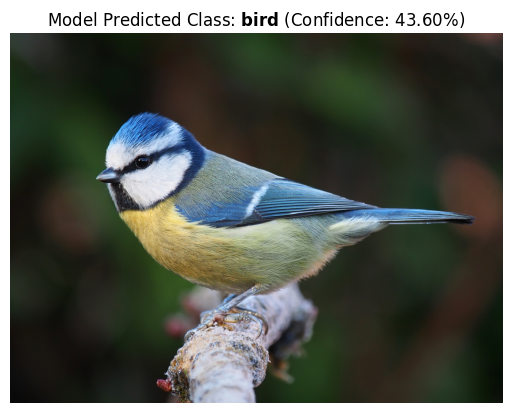

In [39]:
# Use the model to classify the image
ia_classifica_imagem("imagem1.jpg", model_loaded)

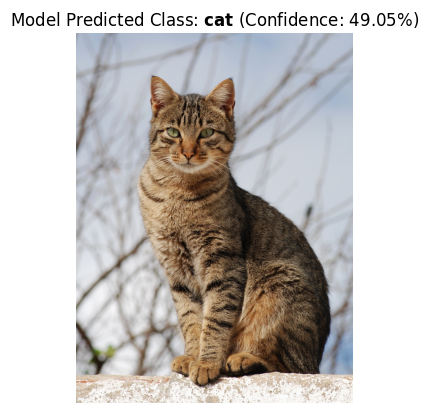

In [40]:
# Use the model to classify the image
ia_classifica_imagem("imagem2.jpg", model_loaded)

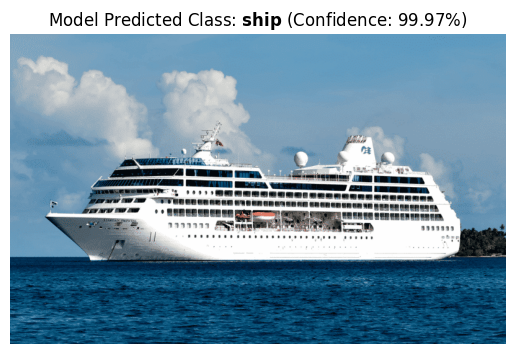

In [41]:
# Use the model to classify the image
ia_classifica_imagem("imagem3.png", model_loaded)

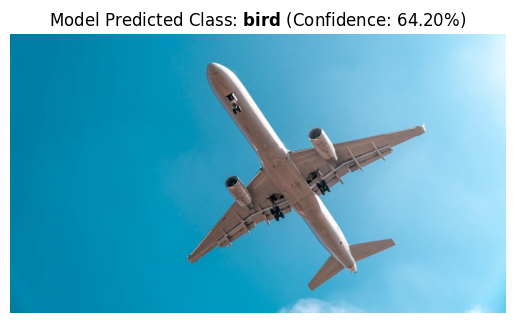

In [42]:
# Use the model to classify the image
ia_classifica_imagem("imagem4.jpg", model_loaded)

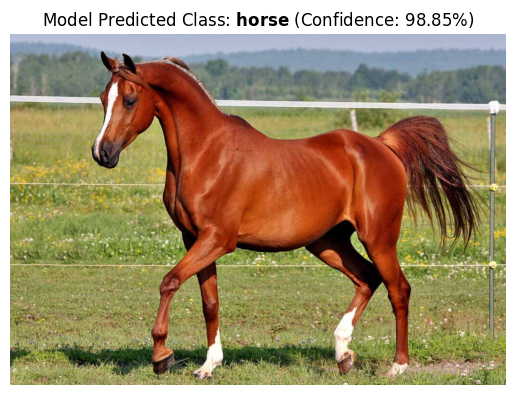

In [43]:
# Use the model to classify the image
ia_classifica_imagem("imagem5.jpg", model_loaded)

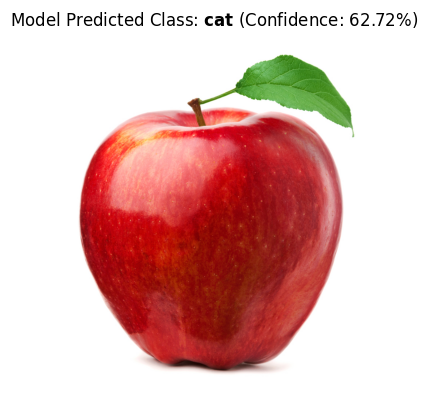

In [44]:
# Use the model to classify the image (note that the model was not trained with apple images)
ia_classifica_imagem("imagem6.jpg", model_loaded)

## Bonus - Comparing Execution Across Different Hardware Types

The objective here is simply to gain a general idea of hardware differences in model training.

- 1- Apple M4 Max with GPU - 45.4 s
- 2- Apple M4 Max without GPU - 1 min 40 s
- 3- Google Colab with A100 GPU (High RAM) - 2 min 33 s
- 4- Google Colab with A100 GPU - 2 min 34 s
- 5- Google Colab with T4 GPU - 2 min 32 s
- 6- Google Colab with CPU - 3 min 34 s

# End